In [ ]:
# Purpose:
#   Subclassify NK cells into functional NK subpopulations using integrated scRNA-seq data.
#
# Summary:
#   - Load Harmony-integrated NK Seurat object
#   - Perform cell-cycle scoring and QC visualization
#   - Identify and remove likely doublet clusters
#   - Recompute neighbors, UMAP, and clustering on cleaned NK cells
#   - Assess cluster purity using Azimuth predicted.celltype.l2 labels
#   - Assign level-3 NK identities based on dominant Azimuth annotation:
#       CD56-dim NK, CD56-bright NK, and Proliferating NK
#   - Save finalized annotated NK object

# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes/functions.R')

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

In [3]:
packageVersion("Seurat")

[1] ‘5.3.1.0’

# Load

In [4]:
celltype = 'NK'

In [5]:
obj = qs::qread(glue("data/03_cleandata/itg_{celltype}.qs"))
obj

An object of class Seurat 
28202 features across 38197 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [6]:
exp.mat <- read.table(
    file = "data/geneset/nestorawa_forcellcycle_expressionMatrix.txt",
    header = TRUE, as.is = TRUE, row.names = 1)

s.genes <- cc.genes$s.genes
g2m.genes <- cc.genes$g2m.genes

In [7]:
obj <- CellCycleScoring(obj, 
                        s.features = s.genes, 
                        g2m.features = g2m.genes, 
                        set.ident = TRUE)


Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


# Annotate

In [8]:
colnames(obj@meta.data)

[1] "nFeaturess_RNA"              "nFeaturess_RNA_by_counts"   
 [3] "total_counts"                "total_counts_mt"            
 [5] "pct_counts_mt"               "doublets_pred"              
 [7] "doublets_score"              "nCount_RNA"                 
 [9] "nFeature_RNA"                "percent.mt"                 
[11] "predicted.celltype.l1.score" "predicted.celltype.l1"      
[13] "predicted.celltype.l2.score" "predicted.celltype.l2"      
[15] "predicted.celltype.l3.score" "predicted.celltype.l3"      
[17] "mapping.score"               "RNA_snn_res.0.8"            
[19] "seurat_clusters"             "dataset_name"               
[21] "RNA_snn_res.0.1"             "S.Score"                    
[23] "G2M.Score"                   "Phase"                      
[25] "old.ident"

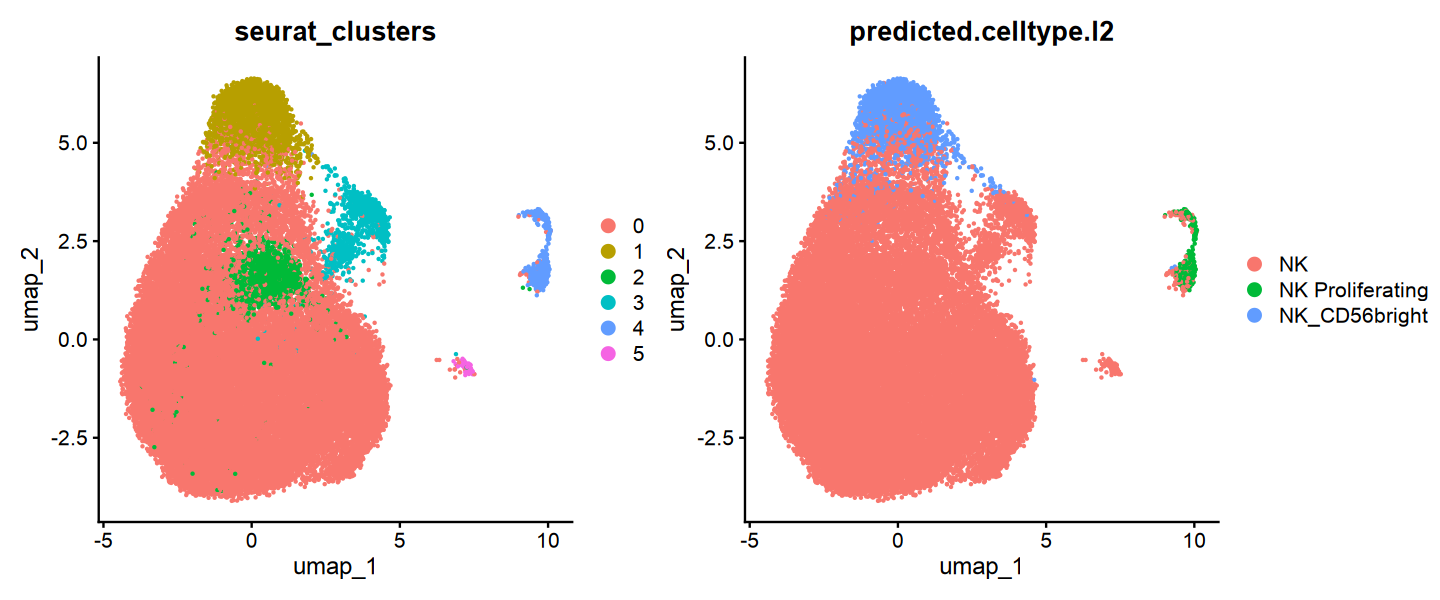

In [9]:
options(repr.plot.width=12, repr.plot.height=5)

DimPlot(obj, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

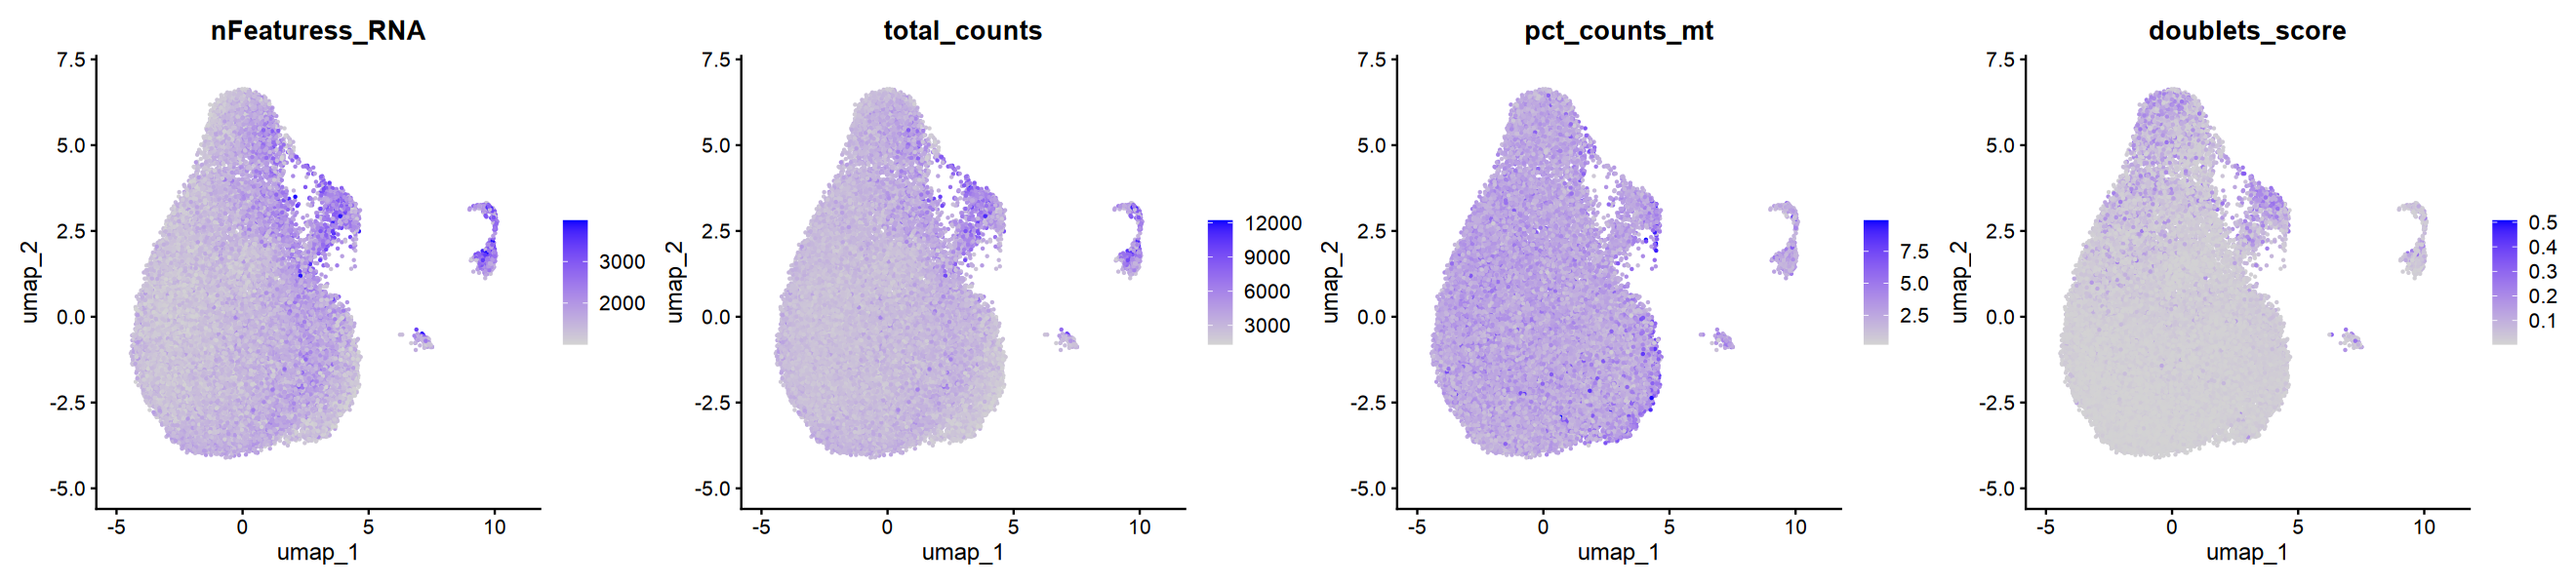

In [10]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(obj, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


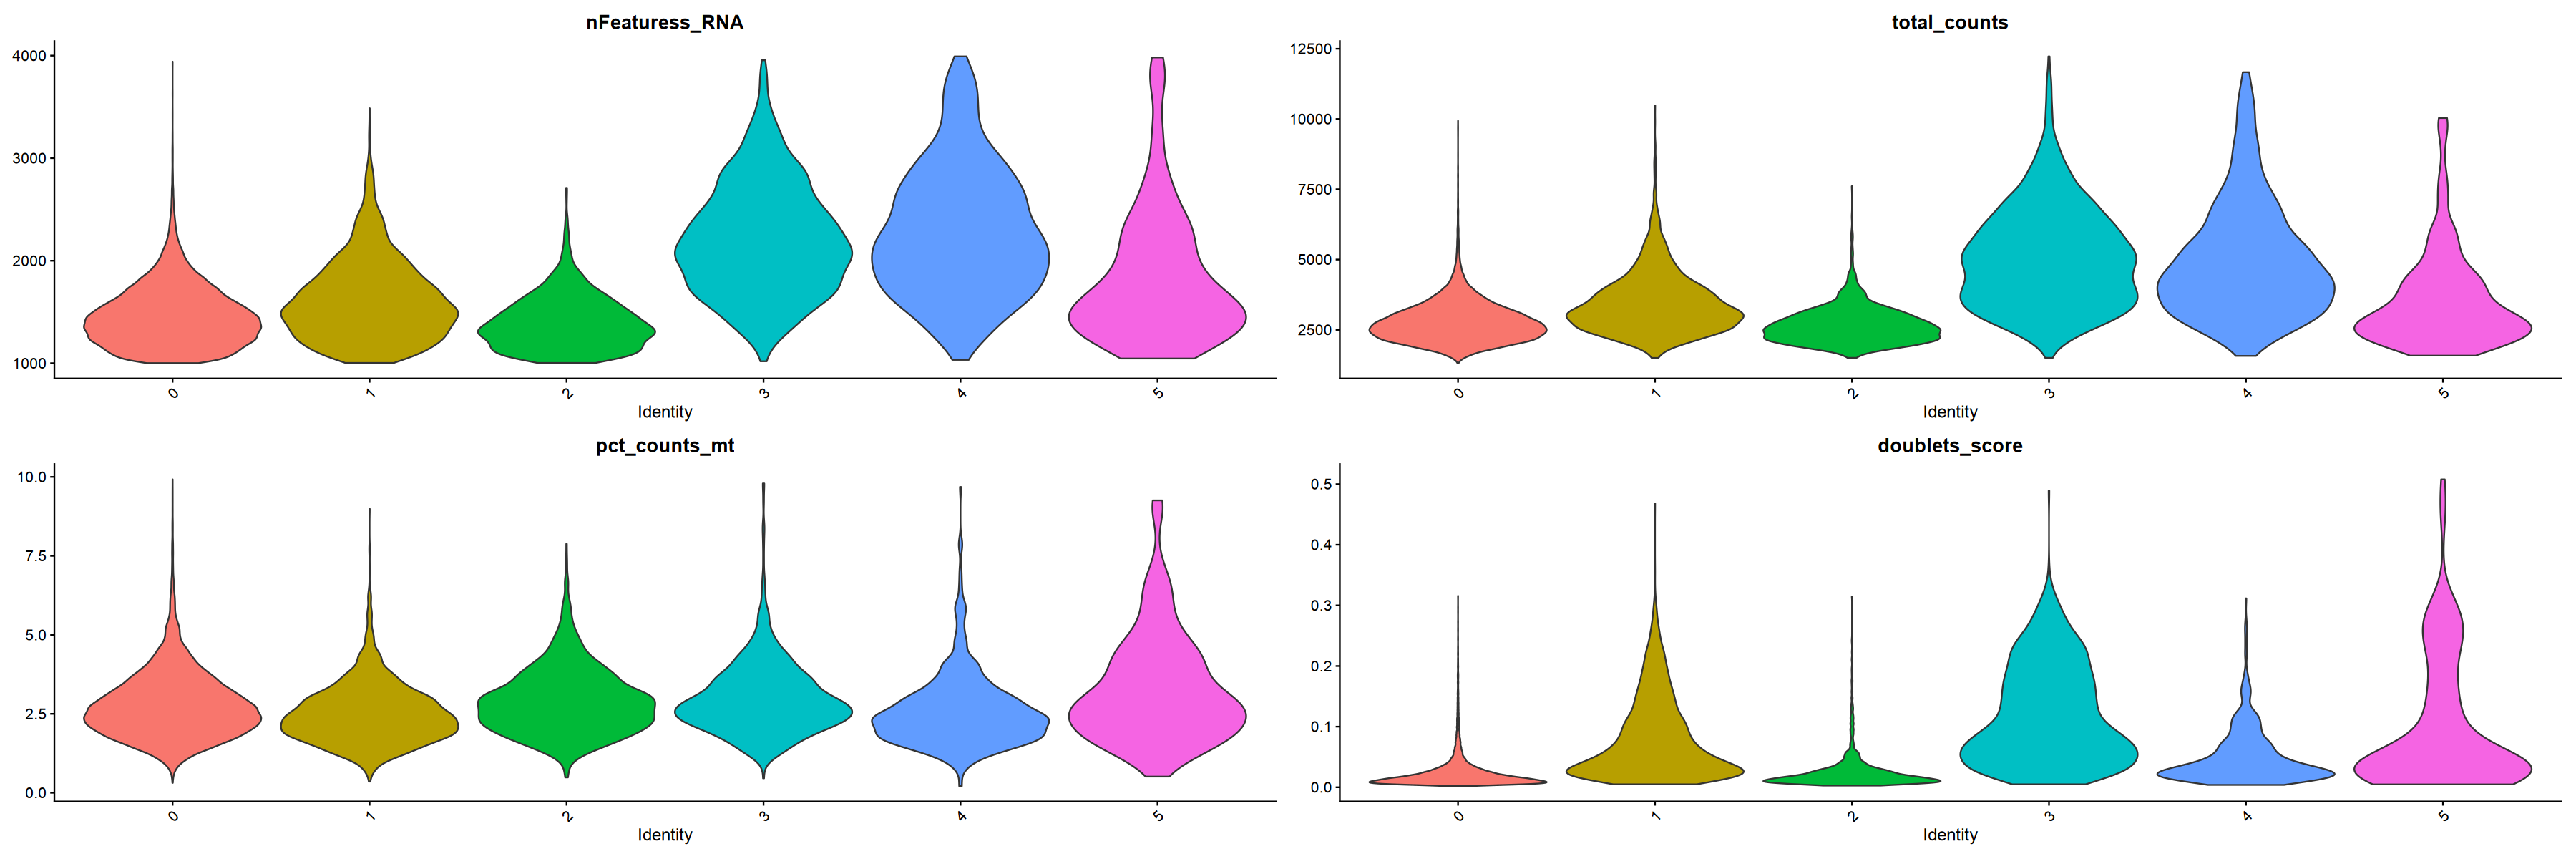

In [11]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

The default behaviour of split.by has changed.
Separate violin plots are now plotted side-by-side.
To restore the old behaviour of a single split violin,
set split.plot = TRUE.
      
This message will be shown once per session.

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


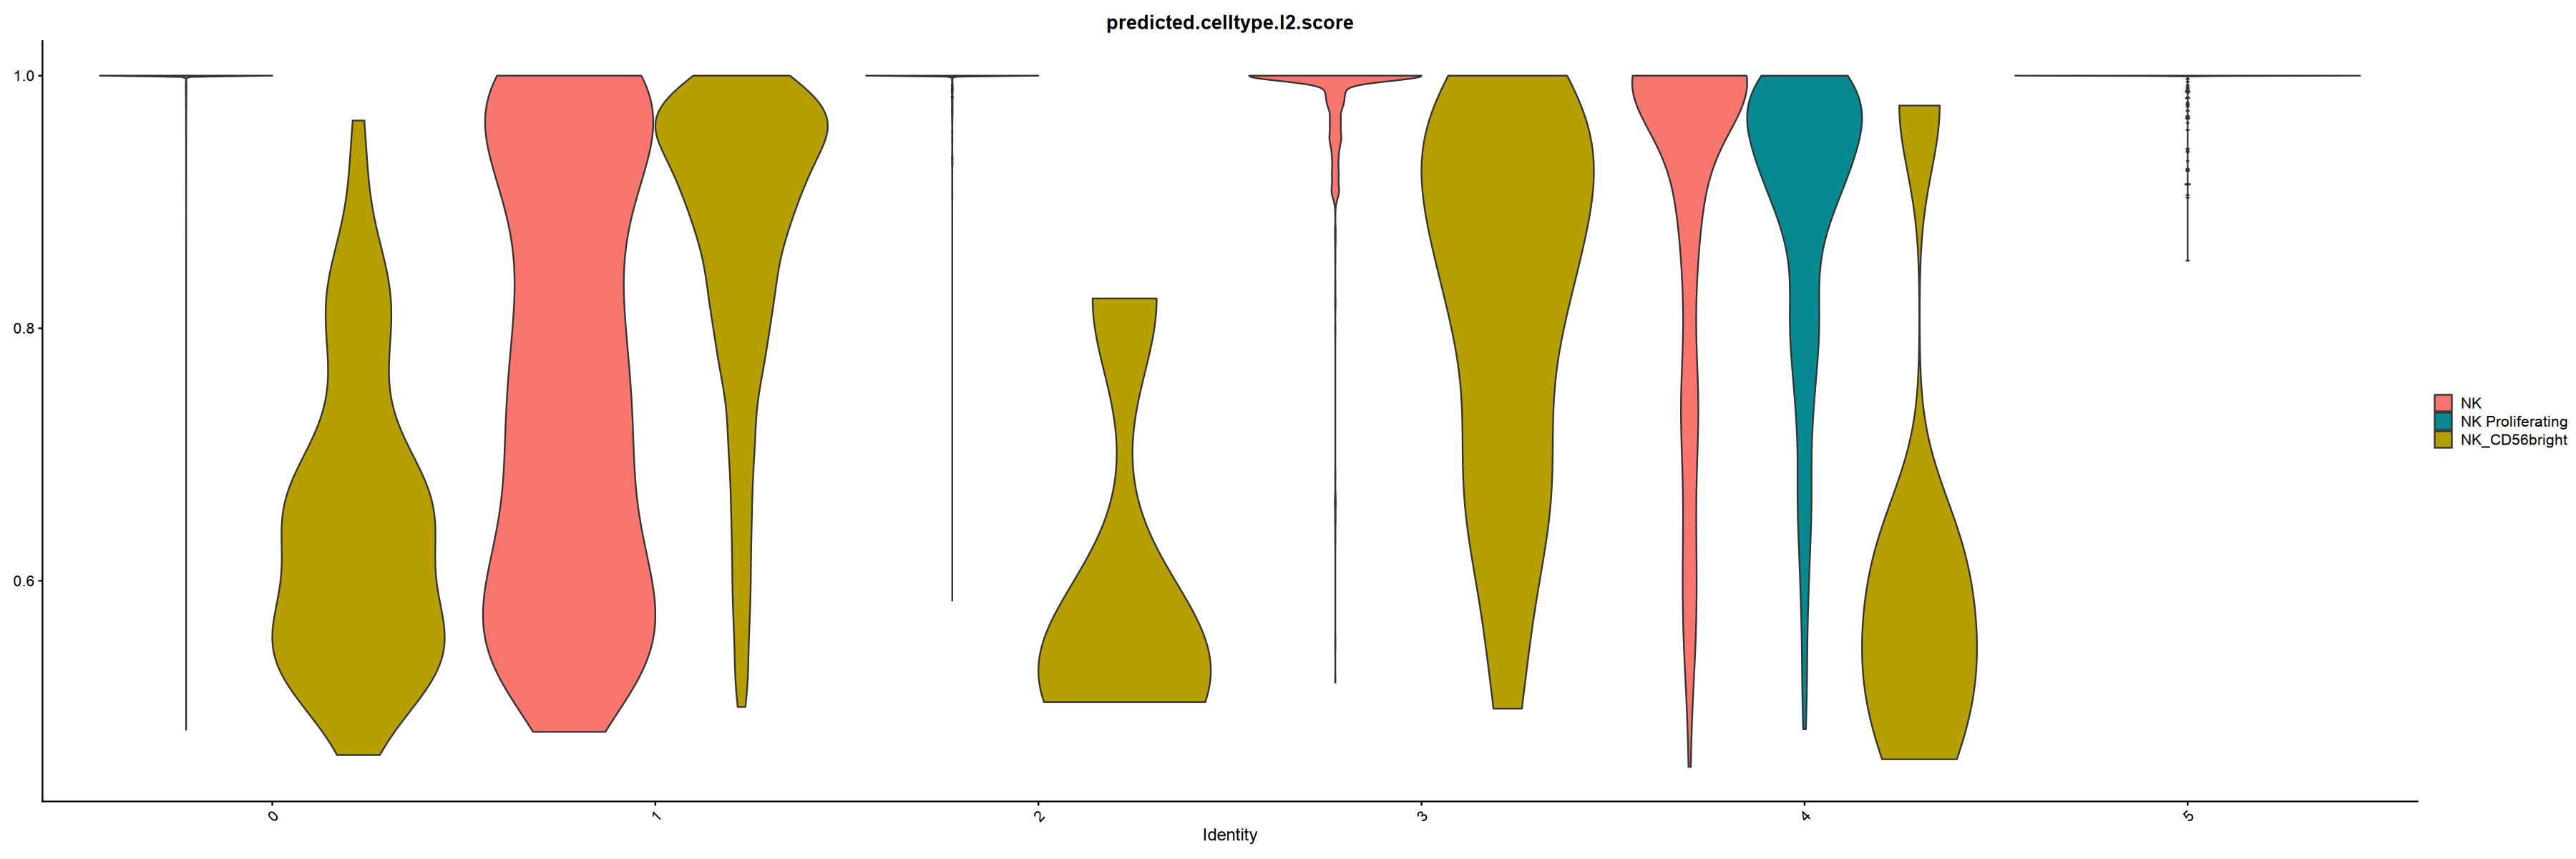

In [12]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('predicted.celltype.l2.score'),          
        split.by='predicted.celltype.l2', group.by='seurat_clusters', 
        ncol=1, pt.size=0)

In [13]:
# cluster 3 and 5 are likely doublets
# we filter them and redo clustering

ft = subset(x = obj, 
            subset = !(seurat_clusters %in% c(3,5)))

ft

An object of class Seurat 
28202 features across 37050 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [14]:
ft <- FindNeighbors(ft, dims = 1:30, reduction = "harmony")
ft <- RunUMAP(ft, dims = 1:30, reduction = "harmony")

Computing nearest neighbor graph

Computing SNN

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
15:58:25 UMAP embedding parameters a = 0.9922 b = 1.112

15:58:25 Read 37050 rows and found 30 numeric columns

15:58:25 Using Annoy for neighbor search, n_neighbors = 30

15:58:25 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:58:31 Writing NN index file to temp file /tmp/RtmphKXijw/filebfed6250dd72b

15:58:31 Searching Annoy index using 1 thread, search_k = 3000

15:58:48 Annoy recall = 100%

15:58:48 Commencing smooth kNN distance ca

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 37050
Number of edges: 913739

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8844
Number of communities: 9
Elapsed time: 7 seconds


2 singletons identified. 7 final clusters.



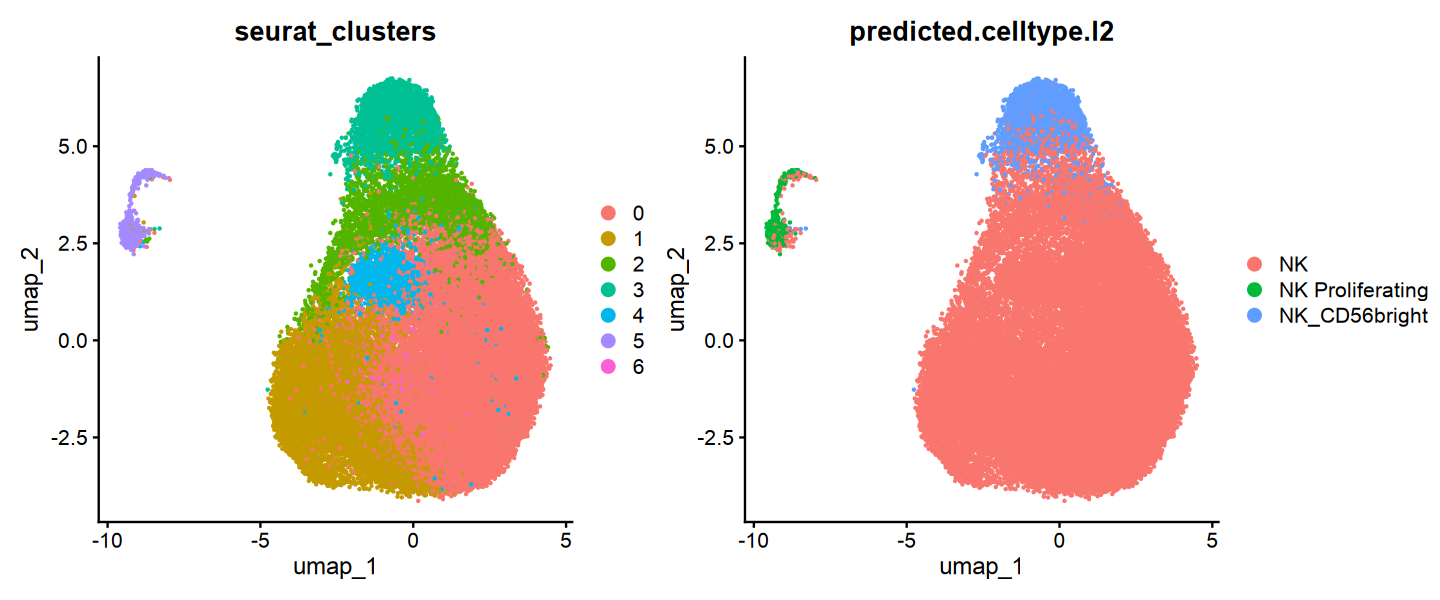

In [47]:
options(repr.plot.width=12, repr.plot.height=5)

ft <- FindClusters(ft, resolution = .2)

DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

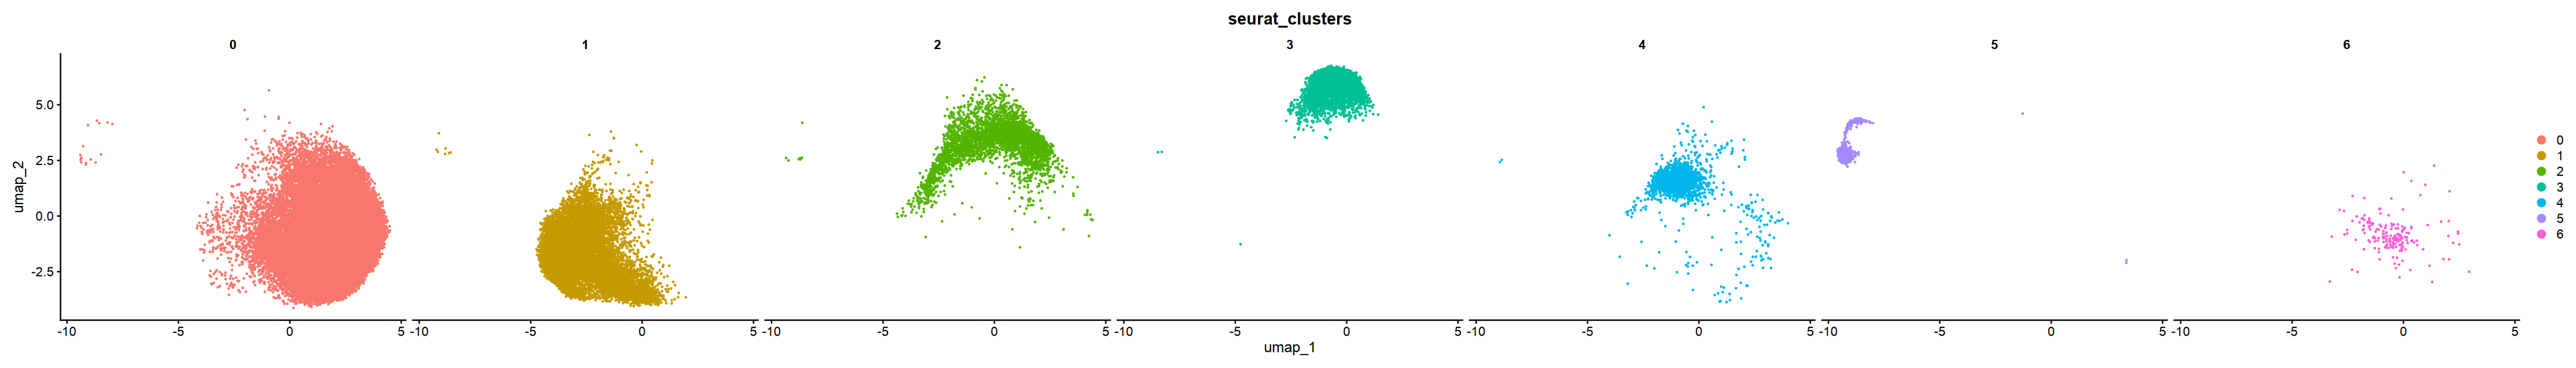

In [48]:
options(repr.plot.width=35, repr.plot.height=5)
varname = 'seurat_clusters'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname,
        ncol=7
       )

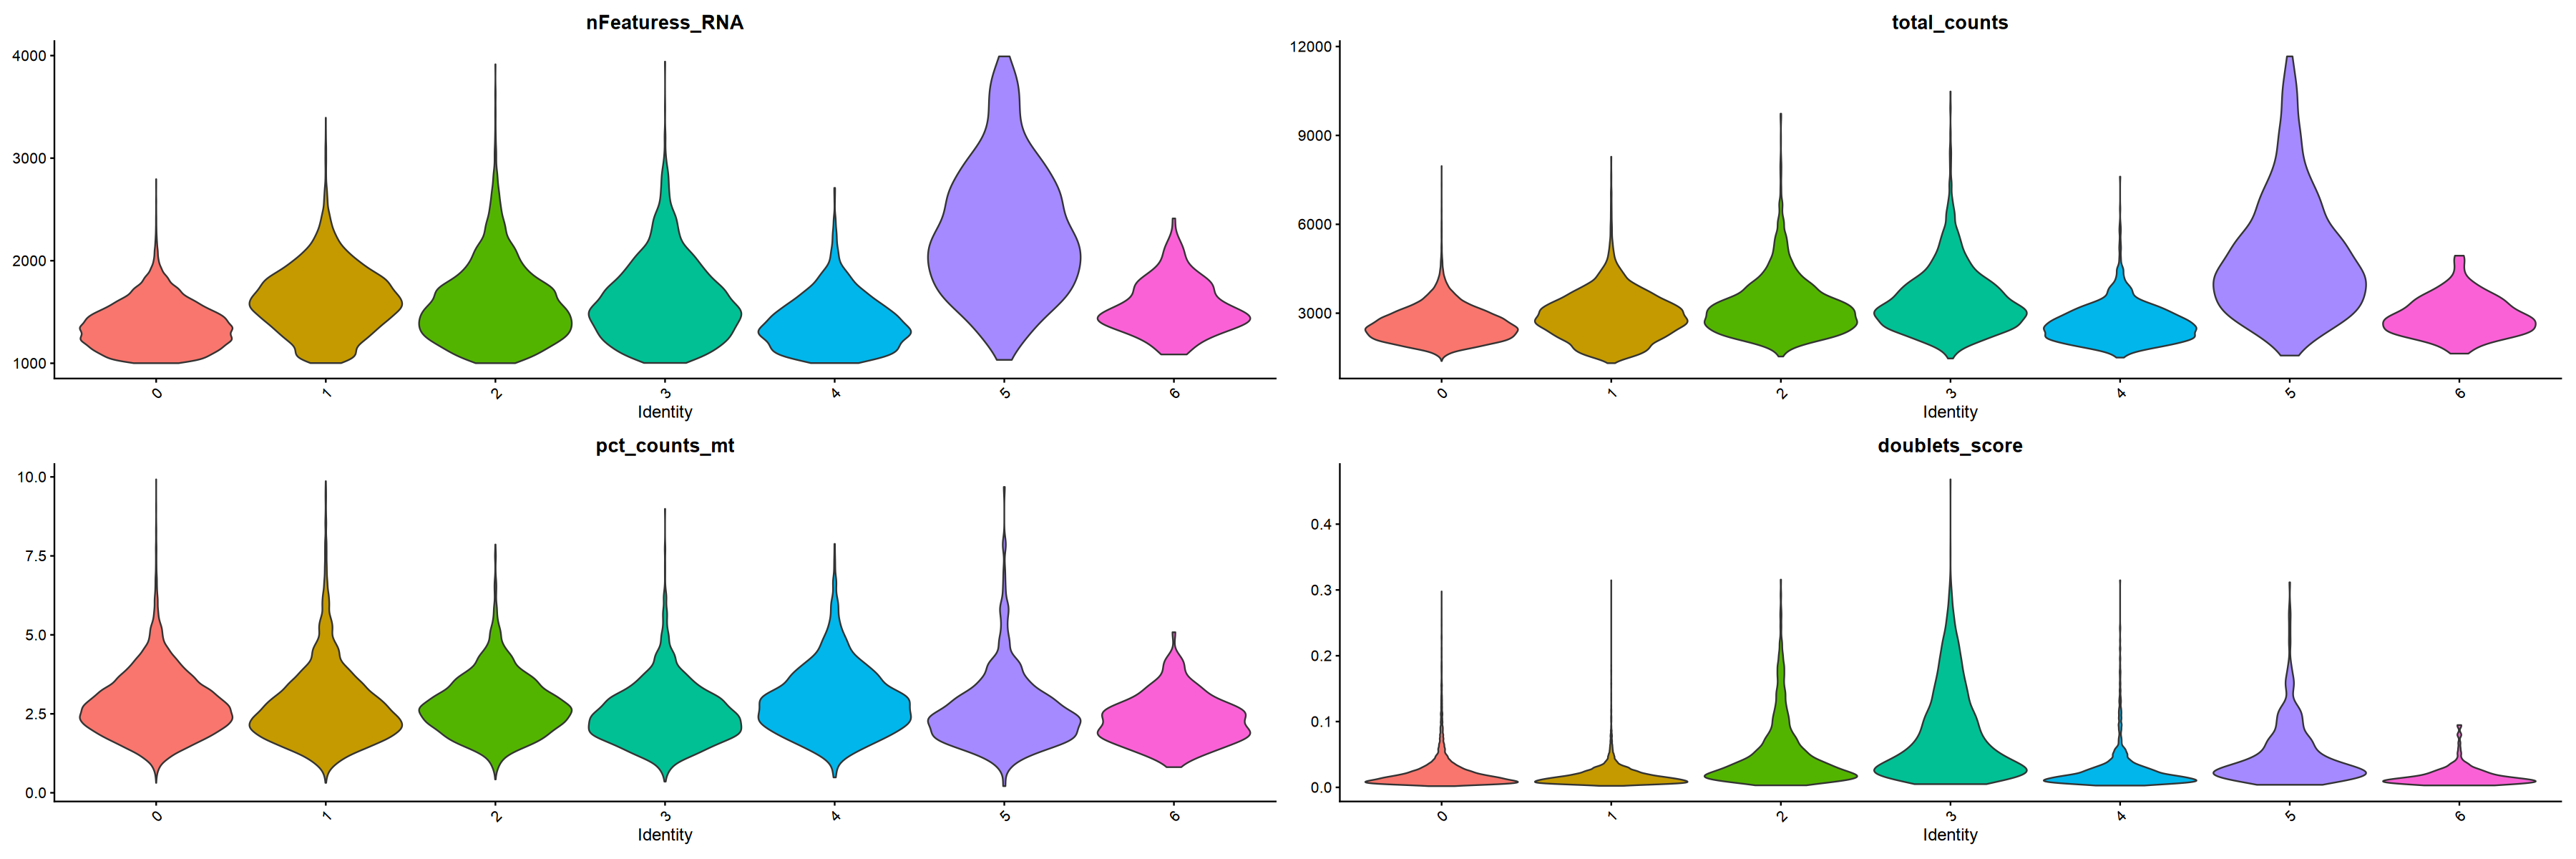

In [49]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

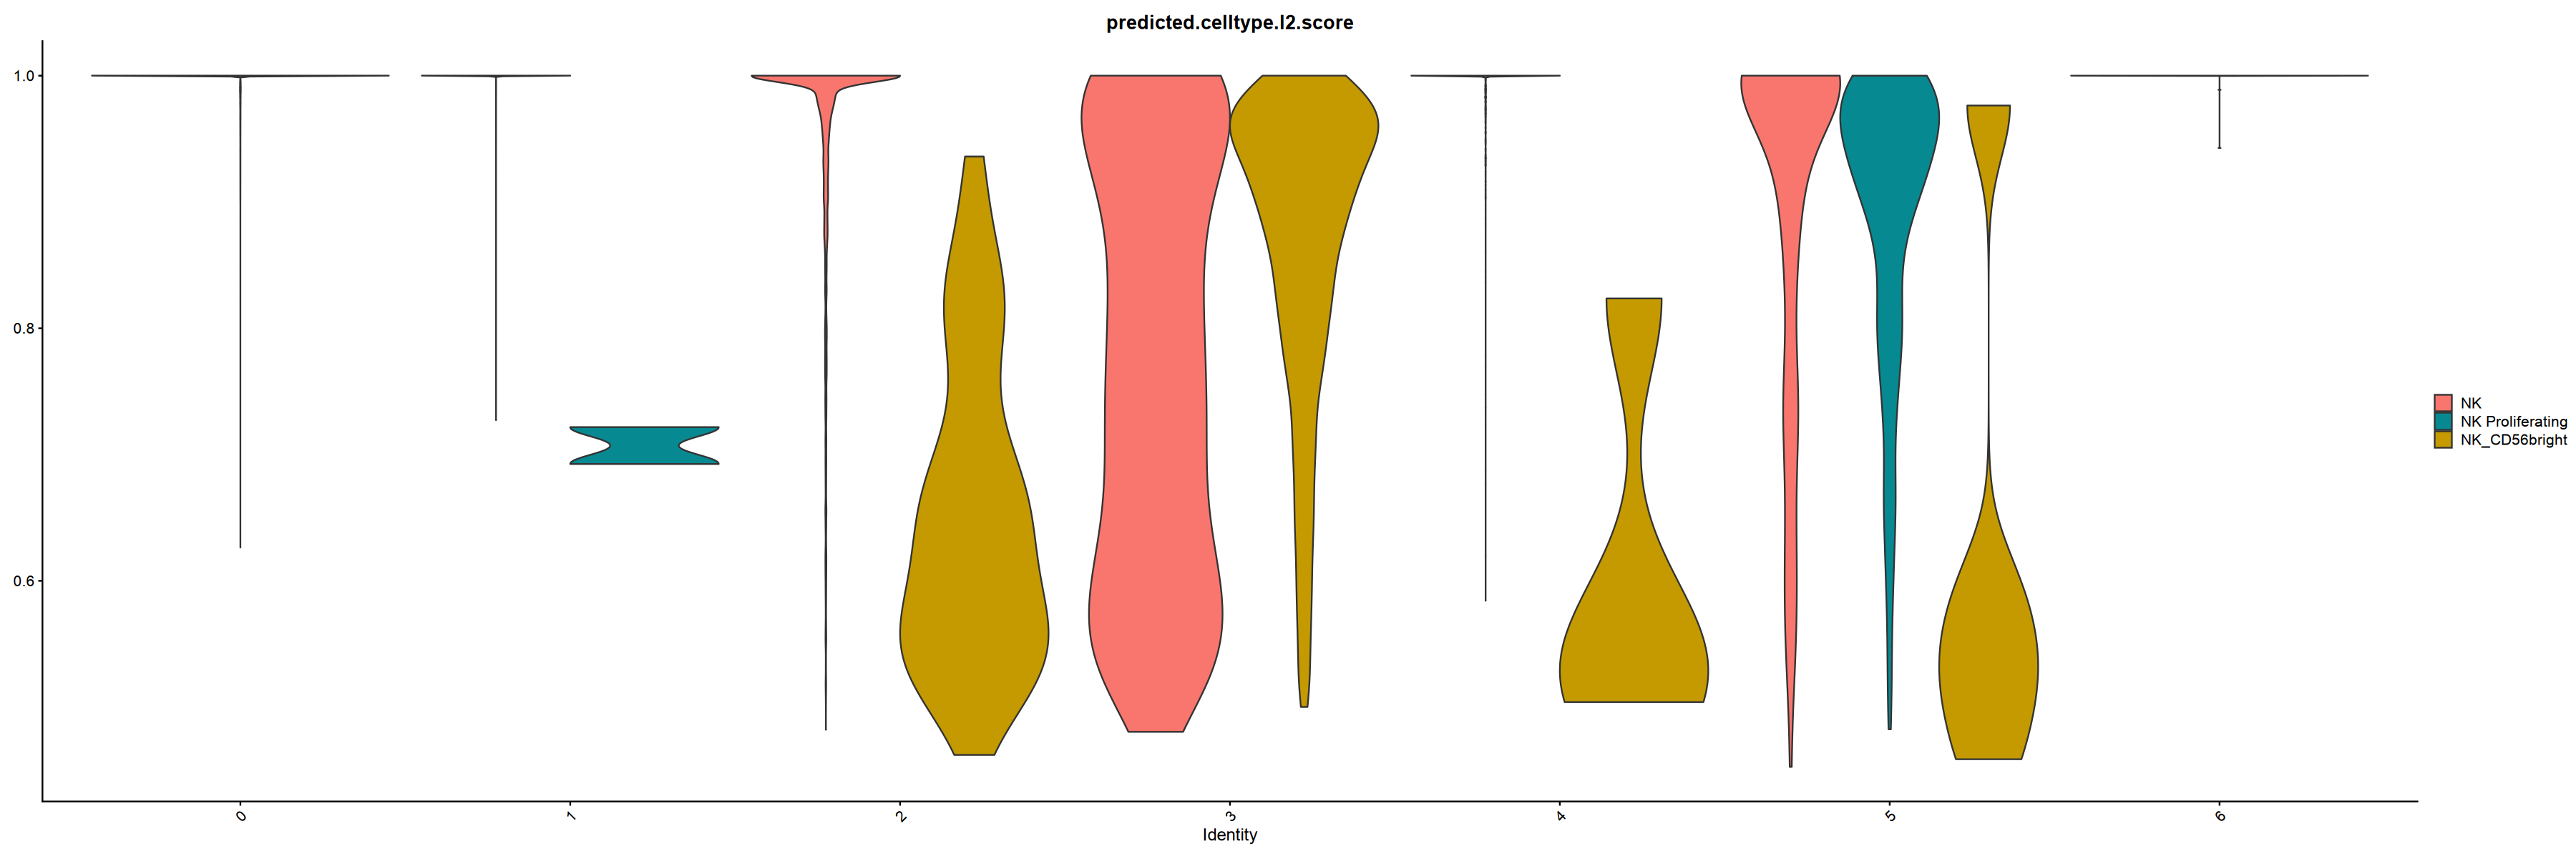

In [50]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('predicted.celltype.l2.score'),          
        split.by='predicted.celltype.l2', group.by='seurat_clusters', 
        ncol=1, pt.size=0)

In [51]:
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
ctab_pct <- as.data.frame.matrix(prop.table(ctab, 1) * 100)

ctab_pct

,NK,NK Proliferating,NK_CD56bright
,<dbl>,<dbl>,<dbl>
0,100.00000,0.00000000,0.0000000
1,99.97792,0.02207506,0.0000000
2,96.99399,0.00000000,3.0060120
3,13.68039,0.00000000,86.3196126
4,99.76148,0.00000000,0.2385212
5,29.37956,69.70802920,0.9124088
6,100.00000,0.00000000,0.0000000


In [52]:
max_pct <- apply(ctab_pct, 1, max)
clusters_low_purity <- as.integer(names(max_pct[max_pct < 60]) )
print(clusters_low_purity)

integer(0)


In [53]:
# for those cells which are not in clusters_low_purity, assign top predicted.celltype.l2 for that seurat_clusters
# Assume ft is your Seurat object and clusters_low_purity is already defined

# Step 1: Get cluster to top cell type mapping
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
cluster_majority <- apply(ctab, 1, function(x) names(x)[which.max(x)])

# Step 2: For cells NOT in clusters_low_purity, assign top celltype
valid_clusters <- setdiff(as.integer(rownames(ctab)), clusters_low_purity)

meta_tmp <- ft@meta.data[,'seurat_clusters', drop=F]
meta_tmp$celltype_level3 <- NA  # initialize

mask <- meta_tmp$seurat_clusters %in% valid_clusters
meta_tmp$celltype_level3[mask] <- cluster_majority[as.character(meta_tmp$seurat_clusters[mask])]

anno1 = meta_tmp %>% drop_na()
dim(anno1)                       
head(anno1  )   

[1] 37050     2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGAGGGATGGG-1,0,NK
Pool137_10_AAACCTGGTGCTCTTC-1,0,NK
Pool137_10_AAACGGGAGCAGGCTA-1,3,NK_CD56bright
Pool137_10_AAACGGGAGTCTTGCA-1,0,NK
Pool137_10_AAACGGGCACGGCTAC-1,0,NK
Pool137_10_AAACGGGGTGCATCTA-1,0,NK


In [54]:
anno = anno1

anno = anno[Cells(ft),]

dim(anno)
head(anno)

[1] 37050     2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGAGGGATGGG-1,0,NK
Pool137_10_AAACCTGGTGCTCTTC-1,0,NK
Pool137_10_AAACGGGAGCAGGCTA-1,3,NK_CD56bright
Pool137_10_AAACGGGAGTCTTGCA-1,0,NK
Pool137_10_AAACGGGCACGGCTAC-1,0,NK
Pool137_10_AAACGGGGTGCATCTA-1,0,NK


In [55]:
ft = AddMetaData(ft, 
                 metadata = anno$celltype_level3, 
                 col.name = "celltype_level3")

## Save

In [56]:
map <- c(
  "NK" = "CD56-dim NK",
  "NK_CD56bright" = "CD56-bright NK",
  "NK Proliferating" = "Proliferating NK"
)

# Map values
ft@meta.data[['celltype_level3']] <- map[ ft@meta.data[['celltype_level3']] ]

In [57]:
cell_ordered = c(
    "CD56-dim NK",
    "CD56-bright NK",
    "Proliferating NK"

)

ft@meta.data[['celltype_level3']] = factor(
    ft@meta.data[['celltype_level3']],
    levels = cell_ordered
)

In [58]:
qs::qsave(ft, glue('data/03_cleandata/ft_{celltype}.qs'))